# Evaluation Metrics for Classification

In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from pathlib import Path
from pprint import pprint

np.set_printoptions(legacy='1.25')

In [2]:
DATA_PATH = Path("../datasets").resolve()
datasets = list(DATA_PATH.glob("*.csv", case_sensitive=False))
datasets

[WindowsPath('D:/Users/Esperine/Workspace3/mlzc-main/datasets/data.csv'),
 WindowsPath('D:/Users/Esperine/Workspace3/mlzc-main/datasets/WA_Fn-UseC_-Telco-Customer-Churn.csv')]

In [3]:
df = pd.read_csv(datasets[1])
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Preliminaries

In [4]:
def normalize_name(s: str) -> str:
    # Insert underscore between consecutive capitals followed by lowercase 
    # (e.g., 'XMLHttp' -> 'XML_Http')
    s = re.sub(r"([A-Z]+)([A-Z][a-z])", r"\1_\2", s)
    # Insert underscore between lowercase/numbers and following uppercase 
    # (e.g., 'HttpReq' -> 'Http_Req')
    s = re.sub(r"([a-z\d])([A-Z])", r"\1_\2", s)

    return s.lower()

# Normalize column names
df.columns = df.rename(columns=normalize_name).columns

# Fix format in each categorical variables
categorical_columns = list(df.dtypes[df.dtypes == "str"].index)
for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

# Fill NULLs with zero in `total_charges`
df["total_charges"] = pd.to_numeric(df["total_charges"], errors="coerce").fillna(0)

# Convert `churn` into binary values
df["churn"] = (df["churn"] == "yes").astype(int)

In [5]:
df.head().transpose()

,0,1,2,3,4
customer_id,7590-vhveg,5575-gnvde,3668-qpybk,7795-cfocw,9237-hqitu
gender,female,male,male,male,female
senior_citizen,0,0,0,0,0
partner,yes,no,no,no,no
dependents,no,no,no,no,no
tenure,1,34,2,45,2
phone_service,no,yes,yes,no,yes
multiple_lines,no_phone_service,no,no,no_phone_service,no
internet_service,dsl,dsl,dsl,dsl,fiber_optic
online_security,no,yes,yes,yes,no


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        7043 non-null   str    
 1   gender             7043 non-null   str    
 2   senior_citizen     7043 non-null   int64  
 3   partner            7043 non-null   str    
 4   dependents         7043 non-null   str    
 5   tenure             7043 non-null   int64  
 6   phone_service      7043 non-null   str    
 7   multiple_lines     7043 non-null   str    
 8   internet_service   7043 non-null   str    
 9   online_security    7043 non-null   str    
 10  online_backup      7043 non-null   str    
 11  device_protection  7043 non-null   str    
 12  tech_support       7043 non-null   str    
 13  streaming_tv       7043 non-null   str    
 14  streaming_movies   7043 non-null   str    
 15  contract           7043 non-null   str    
 16  paperless_billing  7043 non-null   

In [7]:
df.nunique()

customer_id          7043
gender                  2
senior_citizen          2
partner                 2
dependents              2
tenure                 73
phone_service           2
multiple_lines          3
internet_service        3
online_security         3
online_backup           3
device_protection       3
tech_support            3
streaming_tv            3
streaming_movies        3
contract                3
paperless_billing       2
payment_method          4
monthly_charges      1585
total_charges        6531
churn                   2
dtype: int64

In [8]:
RANDOM_SEED = 1

# Train, Val, Test split
df_full_train, df_test = train_test_split(
    df, 
    test_size=0.2, 
    random_state=RANDOM_SEED
)
df_train, df_val = train_test_split(
    df_full_train, 
    test_size=0.25, 
    random_state=RANDOM_SEED
)

# Resetting indices
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
# df_full_train = df_full_train.reset_index(drop=True)

# Extract target
y_train = df_train["churn"].values
y_val = df_val["churn"].values
y_test = df_test["churn"].values
# y_full_train = df_full_train["churn"].values

# Remove target from dataframes
df_train.drop("churn", axis=1, inplace=True)
df_val.drop("churn", axis=1, inplace=True)
df_test.drop("churn", axis=1, inplace=True)
# df_full_train.drop("churn", axis=1, inplace=True)

In [9]:
numerical_features = ["tenure", "monthly_charges", "total_charges"]
pprint(numerical_features)

exclude_cols = numerical_features[:]
exclude_cols.extend(["churn", "customer_id"])
categorical_features = df_full_train.columns.difference(exclude_cols, sort=False).to_list()
pprint(categorical_features)

all_features = categorical_features + numerical_features
print(len(all_features))

['tenure', 'monthly_charges', 'total_charges']
['gender',
 'senior_citizen',
 'partner',
 'dependents',
 'phone_service',
 'multiple_lines',
 'internet_service',
 'online_security',
 'online_backup',
 'device_protection',
 'tech_support',
 'streaming_tv',
 'streaming_movies',
 'contract',
 'paperless_billing',
 'payment_method']
19


In [10]:
df.shape, df_train.shape, df_val.shape, df_test.shape, df_full_train.shape

((7043, 21), (4225, 20), (1409, 20), (1409, 20), (5634, 21))

In [11]:
df_train[all_features].info()

<class 'pandas.DataFrame'>
RangeIndex: 4225 entries, 0 to 4224
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             4225 non-null   str    
 1   senior_citizen     4225 non-null   int64  
 2   partner            4225 non-null   str    
 3   dependents         4225 non-null   str    
 4   phone_service      4225 non-null   str    
 5   multiple_lines     4225 non-null   str    
 6   internet_service   4225 non-null   str    
 7   online_security    4225 non-null   str    
 8   online_backup      4225 non-null   str    
 9   device_protection  4225 non-null   str    
 10  tech_support       4225 non-null   str    
 11  streaming_tv       4225 non-null   str    
 12  streaming_movies   4225 non-null   str    
 13  contract           4225 non-null   str    
 14  paperless_billing  4225 non-null   str    
 15  payment_method     4225 non-null   str    
 16  tenure             4225 non-null   

In [12]:
dv = DictVectorizer(sparse=False)

# One-hot encoding and transform features matrix
train_dict = df_train[all_features].to_dict(orient="records")
X_train = dv.fit_transform(train_dict)

# Model training
model = LogisticRegression(solver="liblinear", random_state=RANDOM_SEED)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_

In [13]:
# Transform features matrix for validation
val_dict = df_val[all_features].to_dict(orient="records")
X_val = dv.transform(val_dict)

# Calculate accuracy based on validation
y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

0.8055358410220014

In [14]:
model.intercept_[0].round(3)

-0.122

In [15]:
model.coef_[0].round(3)

array([ 0.607, -0.058, -0.671, -0.028, -0.094,  0.052, -0.103, -0.071,
       -0.042, -0.08 , -0.376,  0.357, -0.103,  0.002, -0.248,  0.133,
       -0.008,  0.057, -0.103, -0.076,  0.217, -0.103, -0.236, -0.249,
        0.127, -0.116, -0.006, -0.101, -0.049,  0.067, -0.04 ,  0.133,
       -0.255,  0.199, -0.101, -0.103,  0.082, -0.064, -0.103,  0.045,
        0.17 , -0.103, -0.189, -0.067,  0.   ])

## Accuracy and dummy model

- Evaluate the model on different thresholds
- Check the accuracy of dummy baselines

In [16]:
len(y_val)

1409

In [17]:
(y_val == churn_decision).mean()

0.8055358410220014

In [18]:
round(len(y_val) * (y_val == churn_decision).mean().item())

1135

In [19]:
from sklearn.metrics import accuracy_score

accuracy_score(y_val, y_pred >= 0.5)

0.8055358410220014

In [20]:
# Checking different thresholds

thresholds = np.linspace(0, 1, 21)
scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print(f"{t:.2f} {score:.3f}")
    scores.append(score)

0.00 0.274
0.05 0.508
0.10 0.605
0.15 0.664
0.20 0.705
0.25 0.738
0.30 0.759
0.35 0.767
0.40 0.781
0.45 0.793
0.50 0.806
0.55 0.804
0.60 0.800
0.65 0.787
0.70 0.766
0.75 0.742
0.80 0.729
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


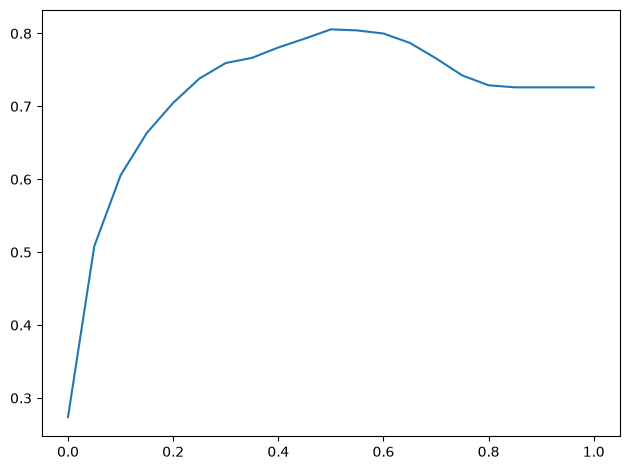

In [21]:
fig, ax = plt.subplots()
ax.plot(thresholds, scores)

plt.tight_layout()

In [22]:
from collections import Counter

# Predict that no customers will churn
# i.e. Set the threshold higher than 1.0
Counter(y_pred >= 1.0)

Counter({False: 1409})

In [23]:
1 - y_val.mean()

0.7260468417317246

Class imbalance 

- Model can get a high accuracy by always predicting the majority class
- From the validation set, only 27% of the customers churned vs. 73% of the customers stayed
- This shows the actual set is skewed and accuracy alone isn't enough to determine how good a model is

## Confusion table

- Think of this topic as an application of Bayes' theorem

In [24]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

In [25]:
t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [26]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()

fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

In [27]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[923, 100],
       [174, 212]])

In [28]:
(confusion_matrix / confusion_matrix.sum()).round(3)

array([[0.655, 0.071],
       [0.123, 0.15 ]])

In [29]:
0.655 + 0.15

0.805

In [30]:
0.123 + 0.071

0.194

- So 65% of all customers are true negatives, 7% false positives, 12% false negatives and 15% true positives.
- Accuracy fits right back in: it is the sum of the diagonal - the correct decisions TN and TP - divided by the total. Here (923 + 212) / 1409 = 0.805, the same ~80% as before. What the table adds is the split of the remaining ~20% into 7% of false positives and 12% of false negatives - two errors with very different business costs.

## Precison and recall

- **Precision** tells us the fraction of positive predictions that are correct
- **Recall** measures the fraction of actual positive instances that we identified correctly

In [31]:
# Precision

p = tp / (tp + fp)
p

0.6794871794871795

In [32]:
# Recall

r = tp / (tp + fn)
r

0.5492227979274611

## ROC Curves (Receiver Operating Characteristic)

### TPR and FPR

1. **True positive rate (TPR)**
    - Fraction of actual positives we identified correctly - it is the same thing as recall
    - TP divided by all positive observations (TP and FN, the second row of the table)
    - **This is the metric we want to maximize**
2. **False positive rate (FPR)**
    - Fraction of actual negatives we got wrong
    - FP divided by all negative observations (FP and TN, the first row of the table)
    - **This is the metric we want to minimize.**

In [33]:
tpr = tp / (tp + fn)
tpr

0.5492227979274611

In [34]:
fpr = fp / (fp + tn)
fpr

0.09775171065493646

In [35]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

In [36]:
columns = ["threshold", "tp", "fp", "fn", "tn"]
df_scores = pd.DataFrame(scores, columns=columns)

df_scores["tpr"] = df_scores["tp"] / (df_scores["tp"] + df_scores["fn"])
df_scores["fpr"] = df_scores["fp"] / (df_scores["fp"] + df_scores["tn"])

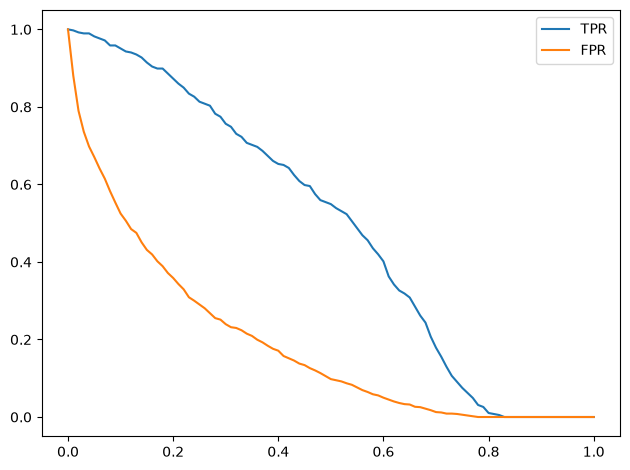

In [37]:
fix, ax = plt.subplots()

ax.plot(df_scores["threshold"], df_scores["tpr"], label="TPR")
ax.plot(df_scores["threshold"], df_scores["fpr"], label="FPR")
ax.legend()

plt.tight_layout()

### Random model

In [38]:
np.random.seed(RANDOM_SEED)
y_rand = np.random.uniform(0, 1, size=len(y_val))

In [39]:
((y_rand >= 0.5) == y_val).mean()

0.5017743080198722

In [40]:
def tpr_fpr_dataframe(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        scores.append((t, tp, fp, fn, tn))

    columns = ["threshold", "tp", "fp", "fn", "tn"]
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores["tpr"] = df_scores["tp"] / (df_scores["tp"] + df_scores["fn"])
    df_scores["fpr"] = df_scores["fp"] / (df_scores["fp"] + df_scores["tn"])
    
    return df_scores

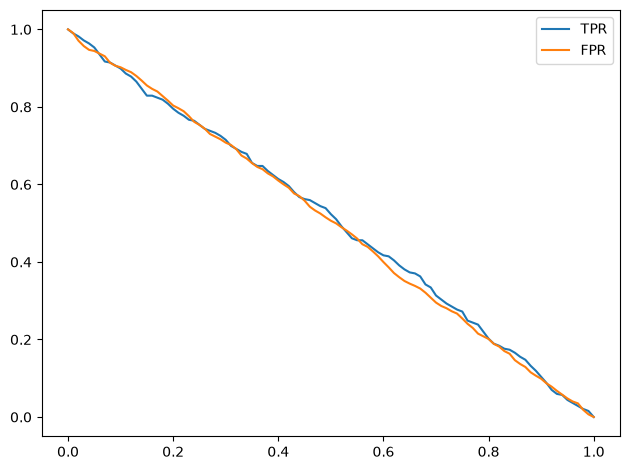

In [41]:
df_rand = tpr_fpr_dataframe(y_val, y_rand)

fix, ax = plt.subplots()

ax.plot(df_rand["threshold"], df_rand["tpr"], label="TPR")
ax.plot(df_rand["threshold"], df_rand["fpr"], label="FPR")
ax.legend()

plt.tight_layout()

### Ideal model

In [42]:
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()
num_neg, num_pos

(1023, 386)

In [43]:
y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal

y_ideal_pred = np.linspace(0, 1, len(y_val))

In [44]:
1 - y_val.mean()

0.7260468417317246

In [45]:
accuracy_score(y_ideal, y_ideal_pred >= 0.726)

1.0

In [46]:
df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_pred)
df_ideal[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,386,882,0,141,1.000000,0.862170
20,0.2,386,741,0,282,1.000000,0.724340
30,0.3,386,600,0,423,1.000000,0.586510
40,0.4,386,459,0,564,1.000000,0.448680
50,0.5,386,319,0,704,1.000000,0.311828
60,0.6,386,178,0,845,1.000000,0.173998
70,0.7,386,37,0,986,1.000000,0.036168
80,0.8,282,0,104,1023,0.730570,0.000000
90,0.9,141,0,245,1023,0.365285,0.000000


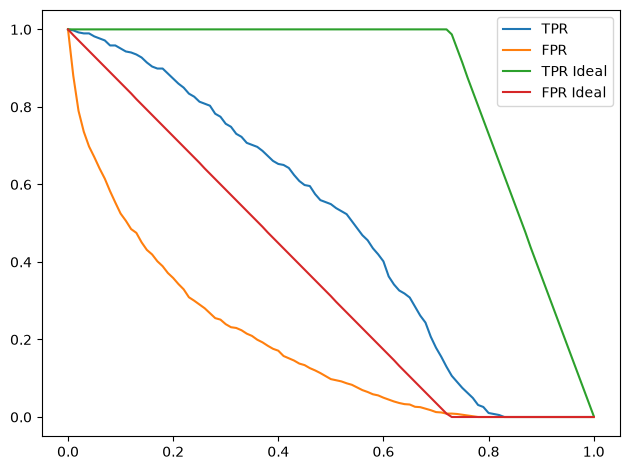

In [47]:
fix, ax = plt.subplots()

ax.plot(df_scores["threshold"], df_scores["tpr"], label="TPR")
ax.plot(df_scores["threshold"], df_scores["fpr"], label="FPR")

ax.plot(df_ideal["threshold"], df_ideal["tpr"], label="TPR Ideal")
ax.plot(df_ideal["threshold"], df_ideal["fpr"], label="FPR Ideal")

# ax.plot(df_rand["threshold"], df_rand["tpr"], label="TPR")
# ax.plot(df_rand["threshold"], df_rand["fpr"], label="FPR")

ax.legend()

plt.tight_layout()

**ROC Curve**

- Plots TPR against FPR
- Each point on the curve is the model operating at one threshold: the bottom-left corner is a conservative model (flag almost nobody, bother almost nobody), the top-right corner flags everybody

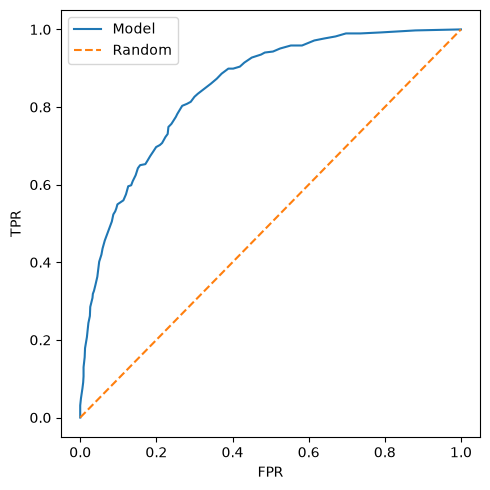

In [48]:
fig, ax = plt.subplots(figsize=(5, 5))

ax.plot(df_scores["fpr"], df_scores["tpr"], label="Model")
ax.plot([0, 1], [0, 1], label="Random", ls="--")

ax.set_xlabel("FPR")
ax.set_ylabel("TPR")
ax.legend()

plt.tight_layout()

In [49]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_val, y_pred)

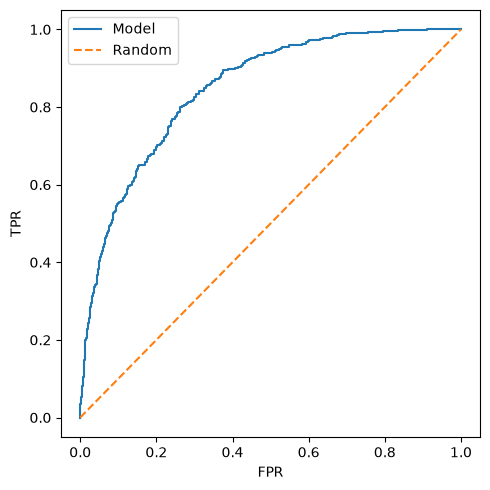

In [50]:
fig, ax = plt.subplots(figsize=(5, 5))

ax.plot(fpr, tpr, label="Model")
ax.plot([0, 1], [0, 1], label="Random", ls="--")

ax.set_xlabel("FPR")
ax.set_ylabel("TPR")
ax.legend()

plt.tight_layout()

## ROC AUC

- Consider the area under the ROC curve
- The AUC score is the probability that a randomly selected positive example has a greater score than a randomly selected negative example
- i.e. Pick a random customer who churned and a random customer who stayed, how likely is it that our model gave the churner the higher risk score?

In [51]:
from sklearn.metrics import auc

auc(fpr, tpr)

0.8465956573929162

In [52]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_val, y_pred)

0.8465956573929162

In [53]:
# Simulation

import random

random.seed(RANDOM_SEED)

neg = y_pred[y_val == 0]
pos = y_pred[y_val == 1]

n = 100_000
success = 0

for i in range(n):
    pos_idx = random.randint(0, len(pos) - 1)
    neg_idx = random.randint(0, len(neg) - 1)

    if pos[pos_idx] > neg[neg_idx]:
        success += 1

success / n

0.8448

In [54]:
n = 50000

np.random.seed(RANDOM_SEED)
pos_idx = np.random.randint(0, len(pos), size=n)
neg_idx = np.random.randint(0, len(neg), size=n)

(pos[pos_idx] > neg[neg_idx]).mean()

0.84892

## Cross Validation

- Evaluating the same model on different subsets of data
- Getting the average prediction and the spread within predictions

In [56]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 4225 entries, 0 to 4224
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        4225 non-null   str    
 1   gender             4225 non-null   str    
 2   senior_citizen     4225 non-null   int64  
 3   partner            4225 non-null   str    
 4   dependents         4225 non-null   str    
 5   tenure             4225 non-null   int64  
 6   phone_service      4225 non-null   str    
 7   multiple_lines     4225 non-null   str    
 8   internet_service   4225 non-null   str    
 9   online_security    4225 non-null   str    
 10  online_backup      4225 non-null   str    
 11  device_protection  4225 non-null   str    
 12  tech_support       4225 non-null   str    
 13  streaming_tv       4225 non-null   str    
 14  streaming_movies   4225 non-null   str    
 15  contract           4225 non-null   str    
 16  paperless_billing  4225 non-null   

In [57]:
categorical_features

['gender',
 'senior_citizen',
 'partner',
 'dependents',
 'phone_service',
 'multiple_lines',
 'internet_service',
 'online_security',
 'online_backup',
 'device_protection',
 'tech_support',
 'streaming_tv',
 'streaming_movies',
 'contract',
 'paperless_billing',
 'payment_method']

In [58]:
numerical_features

['tenure', 'monthly_charges', 'total_charges']

In [59]:
all_features

['gender',
 'senior_citizen',
 'partner',
 'dependents',
 'phone_service',
 'multiple_lines',
 'internet_service',
 'online_security',
 'online_backup',
 'device_protection',
 'tech_support',
 'streaming_tv',
 'streaming_movies',
 'contract',
 'paperless_billing',
 'payment_method',
 'tenure',
 'monthly_charges',
 'total_charges']

In [60]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[all_features].to_dict(orient="records")

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(
        solver="liblinear", 
        C=C, 
        max_iter=1000, 
        random_state=RANDOM_SEED
    )
    model.fit(X_train, y_train)
    
    return dv, model


def predict(df, dv, model):
    dicts = df[all_features].to_dict(orient="records")

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [61]:
dv, model = train(df_train, y_train, C=0.001)

In [62]:
y_pred = predict(df_val, dv, model)

The idea of **k-fold cross-validation**: split the full training dataset into k partitions (folds). Train the model on k-1 folds, evaluate on the remaining one. Repeat k times, so every fold serves as the validation set once, and average the scores.

In [63]:
from sklearn.model_selection import KFold
from tqdm.auto import tqdm

In [64]:
kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
kfold

KFold(n_splits=5, random_state=1, shuffle=True)

In [65]:
df_full_train.head()

,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
1814,5442-pptjy,male,0,yes,yes,12,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.70,258.35,0
5946,6261-rcvns,female,0,no,no,42,yes,no,dsl,yes,...,yes,yes,no,yes,one_year,no,credit_card_(automatic),73.90,3160.55,1
3881,2176-osjuv,male,0,yes,no,71,yes,yes,dsl,yes,...,no,yes,no,no,two_year,no,bank_transfer_(automatic),65.15,4681.75,0
2389,6161-erdgd,male,0,yes,yes,71,yes,yes,dsl,yes,...,yes,yes,yes,yes,one_year,no,electronic_check,85.45,6300.85,0
3676,2364-ufrom,male,0,no,no,30,yes,no,dsl,yes,...,no,yes,yes,no,one_year,no,electronic_check,70.40,2044.75,0


In [66]:
df_full_train[all_features].head()

,gender,senior_citizen,partner,dependents,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,tenure,monthly_charges,total_charges
1814,male,0,yes,yes,yes,no,no,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,12,19.70,258.35
5946,female,0,no,no,yes,no,dsl,yes,yes,yes,yes,no,yes,one_year,no,credit_card_(automatic),42,73.90,3160.55
3881,male,0,yes,no,yes,yes,dsl,yes,yes,no,yes,no,no,two_year,no,bank_transfer_(automatic),71,65.15,4681.75
2389,male,0,yes,yes,yes,yes,dsl,yes,no,yes,yes,yes,yes,one_year,no,electronic_check,71,85.45,6300.85
3676,male,0,no,no,yes,no,dsl,yes,yes,no,yes,yes,no,one_year,no,electronic_check,30,70.40,2044.75


In [67]:
n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_SEED)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train["churn"].values
        y_val = df_val["churn"].values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001 0.825 +- 0.013
C=0.01 0.839 +- 0.009
C=0.1 0.841 +- 0.007
C=0.5 0.841 +- 0.007
C=1 0.841 +- 0.007
C=5 0.841 +- 0.007
C=10 0.841 +- 0.007


In [68]:
scores

[0.8422141281566202,
 0.8452171070056945,
 0.8338350391330523,
 0.8322708160133018,
 0.8522167487684729]

In [69]:
# Training the final model

dv, model = train(df_full_train, df_full_train["churn"].values, C=1.0)
y_pred = predict(df_test, dv, model)

auc = roc_auc_score(y_test, y_pred)
auc

0.8579400803839363